# Satellite altimetry captures variability in the Ibiza Channel: figures

This notebook rebuilds the figures of the manuscript (Figs. 1-4) and of the Supporting Information (Figs. S1-S5).
Each figure has its own section.

| Figure | Content |
|---|---|
| Fig. 1 | Study region, glider sampling, glider and altimetry transport time series |
| Fig. 2 | Monthly climatologies and seasonal joint distributions |
| Fig. 3 | Correlation by season and water mass (table) |
| Fig. 4 | 2023-2024 time series and SWOT velocities after the DANA |
| Fig. S1 | Mean dynamic topography |
| Fig. S2 | All altimetry products and the MedMFC model |
| Fig. S3 | Lomb-Scargle spectra |
| Fig. S4 | MedMFC geostrophic velocity climatology |
| Fig. S5 | Glider transport during the DANA |

Transport units: gliders in Sv; altimetry in m$^2$ s$^{-1}$ (surface transport per unit depth).

In [1]:
import calendar
import string
from types import SimpleNamespace

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.patheffects as path_effects
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as feature
import gsw
from astropy.timeseries import LombScargle
from matplotlib.colors import Normalize, TwoSlopeNorm
from scipy.interpolate import griddata
from scipy.stats import gaussian_kde, linregress, pearsonr

## Setup: constants and helper functions

In [2]:
# Glider endurance line and constants
LAT = 39.0
LON_MIN, LON_MAX = 0.1, 1.13
R_EARTH = 6371000.0
GRAVITY = 9.81
OMEGA = 2 * np.pi / 86164

# Cities drawn on the maps (longitude, latitude)
location = SimpleNamespace(longitude=-0.376, latitude=39.470)  # Valencia
location2 = SimpleNamespace(longitude=2.650, latitude=39.570)  # Palma
location3 = SimpleNamespace(longitude=1.430, latitude=38.907)  # Ibiza

In [ ]:
def section_at_39N(ds):
    """Interpolate sea level product to 39N (between its two nearest rows) and keep 0.1-1.13E."""
    nearest = np.sort(np.argsort(np.abs(ds.lat.values - LAT))[:2])
    small = ds.isel(lat=nearest).sel(lon=slice(0.0, 2.0))
    lon_new = np.unique(np.concatenate([small.lon.values, [LON_MIN, LON_MAX]]))
    return small.interp(lat=LAT, lon=lon_new).sel(lon=slice(LON_MIN, LON_MAX))


def section_at_39N_global(ds):
    """Same as section_at_39N for the 1/8 deg global product, which has missing coastal points."""
    nearest = np.sort(np.argsort(np.abs(ds.lat.values - LAT))[:2])
    small = ds.isel(lat=nearest).sel(lon=slice(0.0, 2.0)).copy()
    lats, lons = small.lat.values, small.lon.values

    i1 = np.where(lats == lats[lats <= LAT][-1])[0][0]
    i2 = np.where(lats == lats[lats >= LAT][0])[0][0]
    j1 = np.where(lons == lons[lons <= LON_MIN][-1])[0][0]
    j2 = np.where(lons == lons[lons >= LON_MIN][0])[0][0]
    corners = [(i1, j1), (i1, j2), (i2, j1), (i2, j2)]

    for var in ("ugos", "vgos"):
        values = small[var].values.copy()
        for t in range(values.shape[0]):
            corner_values = np.array([values[t, i, j] for i, j in corners])
            valid = np.isfinite(corner_values)
            if valid.sum() == 3:
                points = np.array([[lats[i], lons[j]] for (i, j), ok in zip(corners, valid) if ok])
                k = np.where(~valid)[0][0]
                target = np.array([[lats[corners[k][0]], lons[corners[k][1]]]])
                new = griddata(points, corner_values[valid], target, method="linear")
                if not np.isfinite(new[0]):
                    new = griddata(points, corner_values[valid], target, method="nearest")
                values[t, corners[k][0], corners[k][1]] = new[0]
        small[var] = (small[var].dims, values)

    lon_new = np.unique(np.concatenate([lons, [LON_MIN, LON_MAX]]))
    extended = small.reindex(lon=lon_new)
    ends = np.isin(lon_new, [LON_MIN, LON_MAX])
    for var in ("ugos", "vgos"):
        at_ends = small[var].interp(lon=lon_new[ends]).reindex(lon=lon_new)
        extended[var] = xr.where(extended.lon.isin(lon_new[ends]), at_ends, extended[var]).transpose(*small[var].dims)
    return extended.interp(lat=LAT).sel(lon=slice(LON_MIN, LON_MAX))


def zonal_transport(vgos):
    """Net, northward and southward surface transport (m2 s-1) across the section, from vgos(time, lon)."""
    lon = vgos.lon.values
    dx = np.gradient(np.deg2rad(lon)) * R_EARTH * np.cos(np.deg2rad(LAT))
    dx = xr.DataArray(dx, coords=[vgos.lon], dims=["lon"])
    net = (vgos * dx).sum(dim="lon")
    north = (vgos.where(vgos > 0) * dx).sum(dim="lon")
    south = (vgos.where(vgos < 0) * dx).sum(dim="lon")
    return net, north, south


def monthly_climatology(north, south, end):
    """Monthly climatology (up to `end`) of the net transport."""
    north = north.sel(time=slice(None, end)).groupby("time.month").mean("time")
    south = south.sel(time=slice(None, end)).groupby("time.month").mean("time")
    return north + south


def lomb_scargle_spectrum(da, nfreq=5000):
    """Normalised Lomb-Scargle power (dimensionless) of an unevenly sampled series; frequencies in cycles per day."""
    t = da.time.values.astype("datetime64[s]").astype(float) / 86400.0
    x = da.values - np.nanmean(da.values)
    freqs = np.linspace(1.0 / (t.max() - t.min()), 0.5 / np.min(np.diff(np.sort(t))), nfreq)
    return freqs, LombScargle(t, x).power(freqs)


def plot_gliders(ax, t_north, y_north, t_south, y_south, color, label):
    """Plot northward and southward transports, breaking the line where there is a gap of more than 20 days."""
    for t, y in ((t_north, y_north), (t_south, y_south)):
        gaps = np.where(np.diff(t) / np.timedelta64(1, "D") > 20)[0]
        for seg in np.split(np.arange(len(t)), gaps + 1):
            ax.plot(t[seg], y[seg], color=color, lw=2)
    ax.plot([], [], color=color, lw=2, label=label)


def swot_section_transport(l3):
    """Net, northward and southward transport (m2 s-1) of each SWOT cycle along the line closest to 39N."""
    idx = np.abs(l3.lat - LAT).argmin(dim="num_lines")
    lon = l3.lon.isel(num_lines=idx)
    inside = (lon >= LON_MIN) & (lon <= LON_MAX)
    v = l3.vgos_filtered.isel(num_lines=idx).where(inside, drop=True)
    lon = lon.where(inside, drop=True)
    dx = np.abs(np.gradient(np.deg2rad(lon)) * R_EARTH * np.cos(np.deg2rad(LAT)))
    dx = xr.DataArray(dx, dims=["num_pixels"], coords={"num_pixels": lon.num_pixels}).assign_coords(lon=lon)
    return {
        "net": (v * dx).sum(dim="num_pixels"),
        "north": (v.where(v > 0, 0) * dx).sum(dim="num_pixels"),
        "south": (v.where(v < 0, 0) * dx).sum(dim="num_pixels"),
        "time": pd.to_datetime(l3.time[:, 0].values).round("D"),
    }


def closest_index(times, target):
    """Index of the time closest to `target`."""
    return int(np.argmin(np.abs(np.asarray(times).astype("datetime64[ns]") - np.datetime64(target))))

## Data

* **SAT_EUR**: CMEMS L4 regional product (1/16$^\circ$, daily, MDT2020), masked to the western Mediterranean.
* **Gliders**: SOCIB geostrophic transport estimates (Juza et al., 2025).
* **Bathymetry**: from GEBCO (https://www.gebco.net/).

In [4]:
# SAT_EUR
dseur = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/eur_phy_008_068/dt_eur_phy_ssh_allsat_01012011_01052025.nc')
maskeur = xr.open_dataset('../../results/mask/WMED_GIBR_eur.nc')
dseur = dseur.where(maskeur["mask"], drop=True)

a = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/eur_phy_008_068/dt_eur_phy_ssh_allsat_02052025_16012026.nc')
a = a.rename({'longitude': 'lon', 'latitude': 'lat'})
a = a.where(maskeur["mask"], drop=True)
dseur = xr.concat([dseur, a], dim="time")

# SOCIB gliders
glider = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/SOCIB/SOCIB_gliders_geostrophic_transport_estimates_IbizaChannel_2011-2024.nc')

# Bathymetry
bathy = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/Bathy_Ibiza_channel/bathy_westmed.nc')
bathy = bathy.sel(lon=slice(-3, 4), lat=slice(37, 41))
bathy_ocean = np.ma.masked_where(bathy.elevation > 0, bathy.elevation)

### Transports

`SAT_GLI` is SAT_EUR interpolated at the glider crossing times. It separates the sampling effect from the physical effect.

In [5]:
# Surface transport of SAT_EUR across the glider line (m2 s-1)
dseur39 = section_at_39N(dseur)
transeur, transeur_north, transeur_south = zonal_transport(dseur39.vgos)

# Glider net transport (Sv) and crossings used in the comparison
glidernet = glider.northward_transport + glider.southward_transport
gl_sel = glider.sel(time=slice(None, '2024-12-31'))

# SAT_GL: SAT_EUR at the glider times
transeurgl = transeur.interp(time=gl_sel.time)
transeurnorth_gl = transeur_north.interp(time=gl_sel.time)
transeursouth_gl = transeur_south.interp(time=gl_sel.time)

## Fig. 1: study region, glider sampling and transport time series

/home/hargous/anaconda3/envs/paul_eke/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:509: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  return super().draw(renderer=renderer, **kwargs)


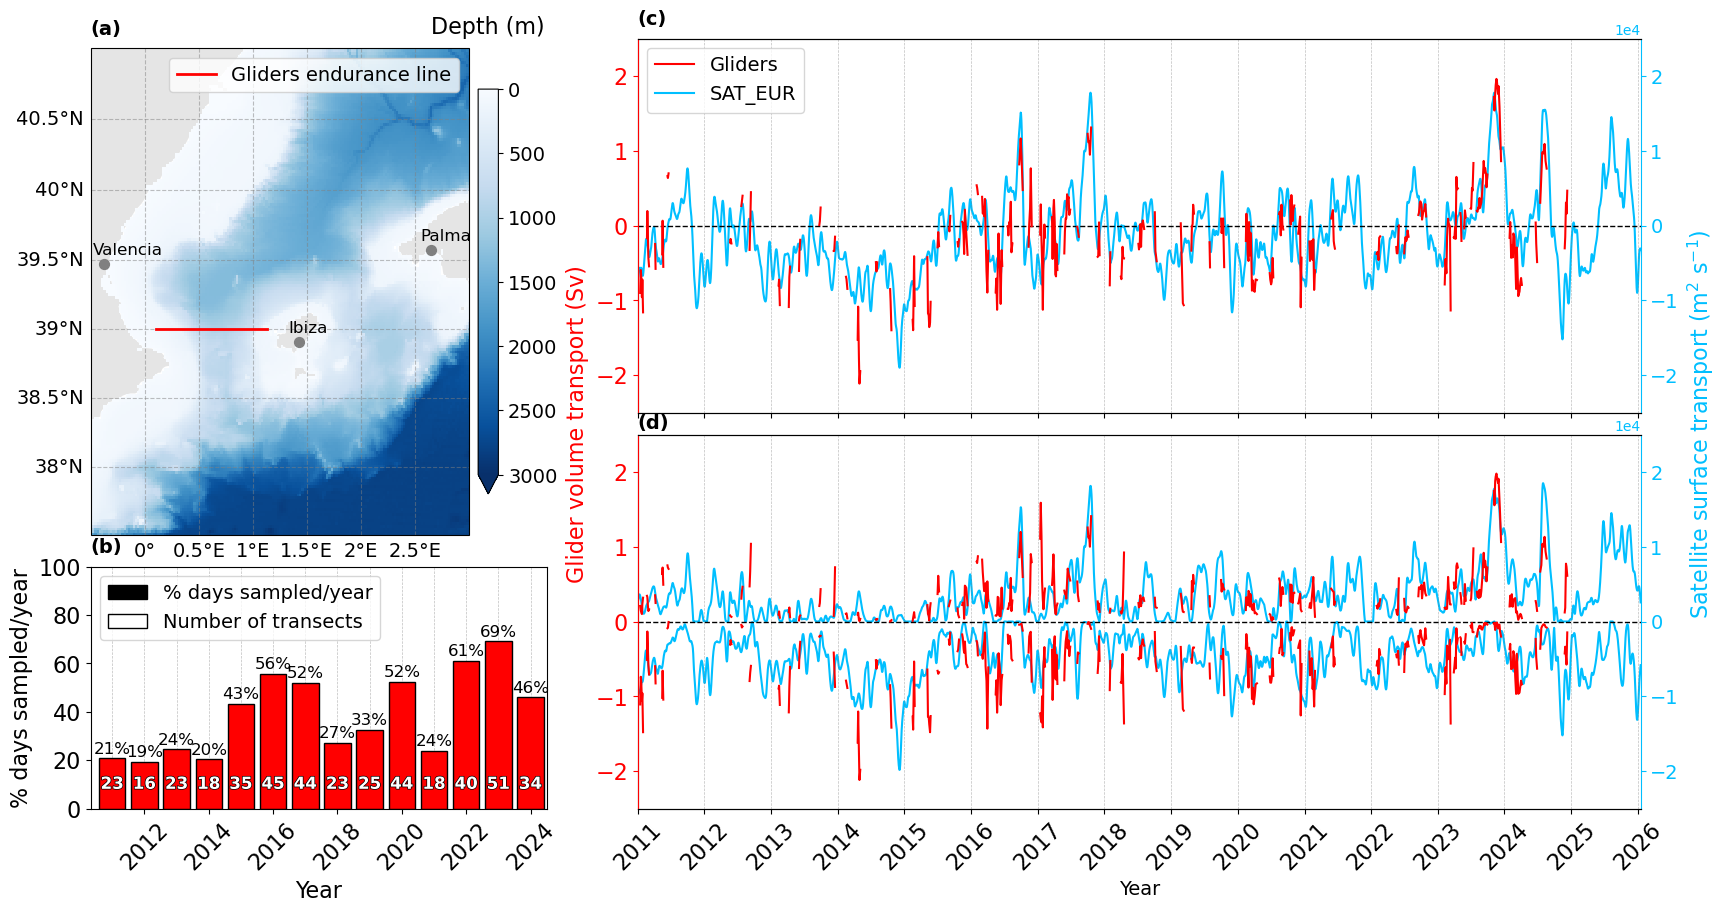

In [ ]:
fig = plt.figure(figsize=(20, 10))

gs = gridspec.GridSpec(6, 3, height_ratios=[1, 1, 1, 1, 1, 1], width_ratios=[1, 1, 1], figure=fig)

ax1 = fig.add_subplot(gs[0:4, 0], projection=ccrs.Mercator())
ax2 = fig.add_subplot(gs[4:, 0])
ax3 = fig.add_subplot(gs[0:3, 1:])
ax4 = fig.add_subplot(gs[3:6, 1:])

ax1.add_feature(feature.LAND, facecolor="grey", alpha=0.2)
gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linestyle="--", color="gray", alpha=0.5)
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
gl.top_labels = gl.right_labels = False
ax1.set_extent([-0.5, 3, 37.5, 41], crs=ccrs.PlateCarree())
step = 5
norm = mpl.colors.Normalize(vmin=0, vmax=3000)
pc = ax1.pcolormesh(
    bathy.lon[::step],
    bathy.lat[::step],
    -bathy_ocean[::step, ::step],
    cmap="Blues",
    norm=norm,
    transform=ccrs.PlateCarree(),
    shading="auto",
)
cbar = fig.colorbar(pc, ax=ax1, orientation="vertical", pad=0.02, shrink=0.8, extend="max")
cbar.ax.set_title("Depth (m)", fontsize=16, pad=40)
cbar.set_ticks(np.arange(0, 3001, 500))
cbar.ax.invert_yaxis()
cbar.ax.tick_params(labelsize=14)

lons = [0.1, 1.13]
lats = [39, 39]
ax1.plot(
    lons,
    lats,
    color="#FF0000",
    linewidth=2,
    transform=ccrs.PlateCarree(),
    label="Gliders endurance line",
)
ax1.legend(fontsize=14)
ax1.scatter(location.longitude, location.latitude, s=50, transform=ccrs.PlateCarree(), c="grey", zorder=100)
ax1.text(
    location.longitude - 0.1,
    location.latitude + 0.07,
    "Valencia",
    transform=ccrs.PlateCarree(),
    fontsize=12,
)
ax1.scatter(
    location2.longitude,
    location2.latitude,
    s=50,
    transform=ccrs.PlateCarree(),
    c="grey",
    zorder=100,
)
ax1.text(
    location2.longitude - 0.1,
    location2.latitude + 0.07,
    "Palma",
    transform=ccrs.PlateCarree(),
    fontsize=12,
)
ax1.scatter(
    location3.longitude,
    location3.latitude,
    s=50,
    transform=ccrs.PlateCarree(),
    c="grey",
    zorder=100,
)
ax1.text(
    location3.longitude - 0.1,
    location3.latitude + 0.07,
    "Ibiza",
    transform=ccrs.PlateCarree(),
    fontsize=12,
)

years = pd.to_datetime(
    [
        "2011-01-01",
        "2012-01-01",
        "2013-01-01",
        "2014-01-01",
        "2015-01-01",
        "2016-01-01",
        "2017-01-01",
        "2018-01-01",
        "2019-01-01",
        "2020-01-01",
        "2021-01-01",
        "2022-01-01",
        "2023-01-01",
        "2024-01-01",
    ]
)
days_mission = np.array([76, 71, 89, 74, 158, 204, 190, 99, 119, 192, 87, 223, 252, 168])
transects = np.array([23, 16, 23, 18, 35, 45, 44, 23, 25, 44, 18, 40, 51, 34])
days_in_year = np.array([366 if pd.Timestamp(y).is_leap_year else 365 for y in years])
percent = days_mission / days_in_year * 100
bars = ax2.bar(years, percent, width=300, color="#FF0000", align="center", edgecolor="black")
ax2.set_ylabel("% days sampled/year", fontsize=16)
ax2.set_ylim(0, 100)
ax2.set_xlabel("Year", fontsize=16)

for x, p in zip(years, percent):
    ax2.text(x, p + 2, f"{p:.0f}%", ha="center", fontsize=12)
for bar, t in zip(bars, transects):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        10,
        f"{t}",
        ha="center",
        va="center",
        color="white",
        fontsize=12,
        fontweight="bold",
        path_effects=[path_effects.withStroke(linewidth=1, foreground="black")],
    )
percent_patch = mpatches.Patch(facecolor="black", edgecolor="black", label="% days sampled/year")
transect_patch = mpatches.Patch(facecolor="white", edgecolor="black", label="Number of transects")
ax2.legend(handles=[percent_patch, transect_patch], fontsize=14, loc="upper left")

ax3.axhline(0, color="k", linestyle="--", linewidth=1)
dt = np.diff(glider.time.values)
gap = dt > np.timedelta64(10, "D")
data = glidernet.astype(float)
data[1:][gap] = np.nan
ax3.plot(glider.time, data, color="#FF0000", label="Gliders")
ax3.set_ylim(-2.5, 2.5)

axx3 = ax3.twinx()
axx3.plot(transeur.time, transeur, color="#00BFFF", label="SAT_EUR")
axx3.set_ylim(-25000, 25000)
axx3.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
axx3.set_zorder(0)
ax3.set_zorder(1)
ax3.patch.set_visible(False)
lines_ax3, labels_ax3 = ax3.get_legend_handles_labels()
lines_axx3, labels_axx3 = axx3.get_legend_handles_labels()
ax3.legend(lines_ax3 + lines_axx3, labels_ax3 + labels_axx3, fontsize=14, loc="upper left")
ax3.spines["left"].set_color("#FF0000")
ax3.tick_params(axis="y", colors="#FF0000", labelsize=14)
ax3.spines["right"].set_visible(False)
axx3.spines["right"].set_color("#00BFFF")
axx3.tick_params(axis="y", colors="#00BFFF", labelsize=14)

ax4.axhline(0, color="k", linestyle="--", linewidth=1)
datan = glider.northward_transport.astype(float)
datas = glider.southward_transport.astype(float)
datan[1:][gap] = np.nan
datas[1:][gap] = np.nan
ax4.plot(glider.time, datan, color="#FF0000")
ax4.plot(glider.time, datas, color="#FF0000")
ax4.set_ylim(-2.5, 2.5)
ax4.set_xlabel("Year", fontsize=14)

axx4 = ax4.twinx()
axx4.plot(transeur.time, transeur_north, color="#00BFFF")
axx4.plot(transeur.time, transeur_south, color="#00BFFF")
axx4.set_ylim(-25000, 25000)

axx4.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))

axx4.set_zorder(0)
ax4.set_zorder(1)
ax4.patch.set_visible(False)
ax4.spines["left"].set_color("#FF0000")
ax4.tick_params(axis="y", colors="#FF0000", labelsize=14)
ax4.spines["right"].set_visible(False)
axx4.spines["right"].set_color("#00BFFF")
axx4.tick_params(axis="y", colors="#00BFFF", labelsize=14)

fig.canvas.draw()
y0 = min(ax3.get_position().y0, ax4.get_position().y0)
y1 = max(ax3.get_position().y1, ax4.get_position().y1)
y_center = 0.5 * (y0 + y1)
x_left = min(ax3.get_position().x0, ax4.get_position().x0) - 0.02
x_right = max(axx3.get_position().x1, axx4.get_position().x1) + 0.03
fig.text(
    x_left - 0.01,
    y_center,
    "Glider volume transport (Sv)",
    rotation="vertical",
    va="center",
    ha="center",
    color="#FF0000",
    fontsize=16,
)
fig.text(
    x_right,
    y_center,
    r"Satellite surface transport (m$^{2}$ s$^{-1}$)",
    rotation="vertical",
    va="center",
    ha="center",
    color="#00BFFF",
    fontsize=16,
)

start = pd.Timestamp("2011-01-01")
end = pd.Timestamp("2026-01-16")
year_lines = pd.to_datetime(
    [
        "2011-01-01",
        "2012-01-01",
        "2013-01-01",
        "2014-01-01",
        "2015-01-01",
        "2016-01-01",
        "2017-01-01",
        "2018-01-01",
        "2019-01-01",
        "2020-01-01",
        "2021-01-01",
        "2022-01-01",
        "2023-01-01",
        "2024-01-01",
        "2025-01-01",
        "2026-01-01",
    ]
)
for ax in [ax2, ax3, ax4]:
    ax.set_xlim(start, end)
    ax.tick_params(axis="both", labelsize=16)
    ax.tick_params(axis="x", labelsize=16, rotation=45)
    for y in year_lines:
        ax.axvline(y, color="gray", linestyle="--", linewidth=0.5, alpha=0.5, zorder=0)
year_locator = mdates.YearLocator()
year_formatter = mdates.DateFormatter("%Y")
for ax in [ax2, ax3, ax4]:
    ax.xaxis.set_major_locator(year_locator)
    ax.xaxis.set_major_formatter(year_formatter)

ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(year_formatter)
ax3.tick_params(labelbottom=False)
ax2.set_xlim(pd.Timestamp("2010-05-01"), pd.Timestamp("2024-07-01"))
ax1.set_title("(a)", fontsize=14, fontweight="bold", loc="left", pad=10)
ax2.set_title("(b)", fontsize=14, fontweight="bold", loc="left", pad=10)
ax3.set_title("(c)", fontsize=14, fontweight="bold", loc="left", pad=10)
ax4.set_title("(d)", fontsize=14, fontweight="bold", loc="left", pad=4)
plt.savefig("../../figures/fig01.png", dpi=300, bbox_inches="tight")
plt.show()

## Fig. 2: monthly climatologies and seasonal joint distributions

Climatologies cover 2011-2022. Gliders: Sv. Satellite: m$^2$ s$^{-1}$.

In [7]:
CLIM_END = '2022-12-31'

# Gliders: mean northward and southward transports of each month, then summed
glider_month = glider.sel(time=slice(None, CLIM_END)).groupby('time.month').mean('time')
north = glider_month['northward_transport']
south = glider_month['southward_transport']
climatologie_mensuelle_mean = (
    np.array(north.where(north > 0, 0).values, dtype=float)
    - np.array(np.abs(south.where(south < 0, 0)).values, dtype=float)
)

# SAT_GL: satellite at the glider times
climatologie_mensuelle_meansat = monthly_climatology(transeurnorth_gl, transeursouth_gl, CLIM_END)
# SAT_EUR: all days
climatologie_mensuelle_meansat2 = monthly_climatology(transeur_north, transeur_south, CLIM_END)

/tmp/ipykernel_193326/397239744.py:256: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_kde = cm.get_cmap("viridis", 10)


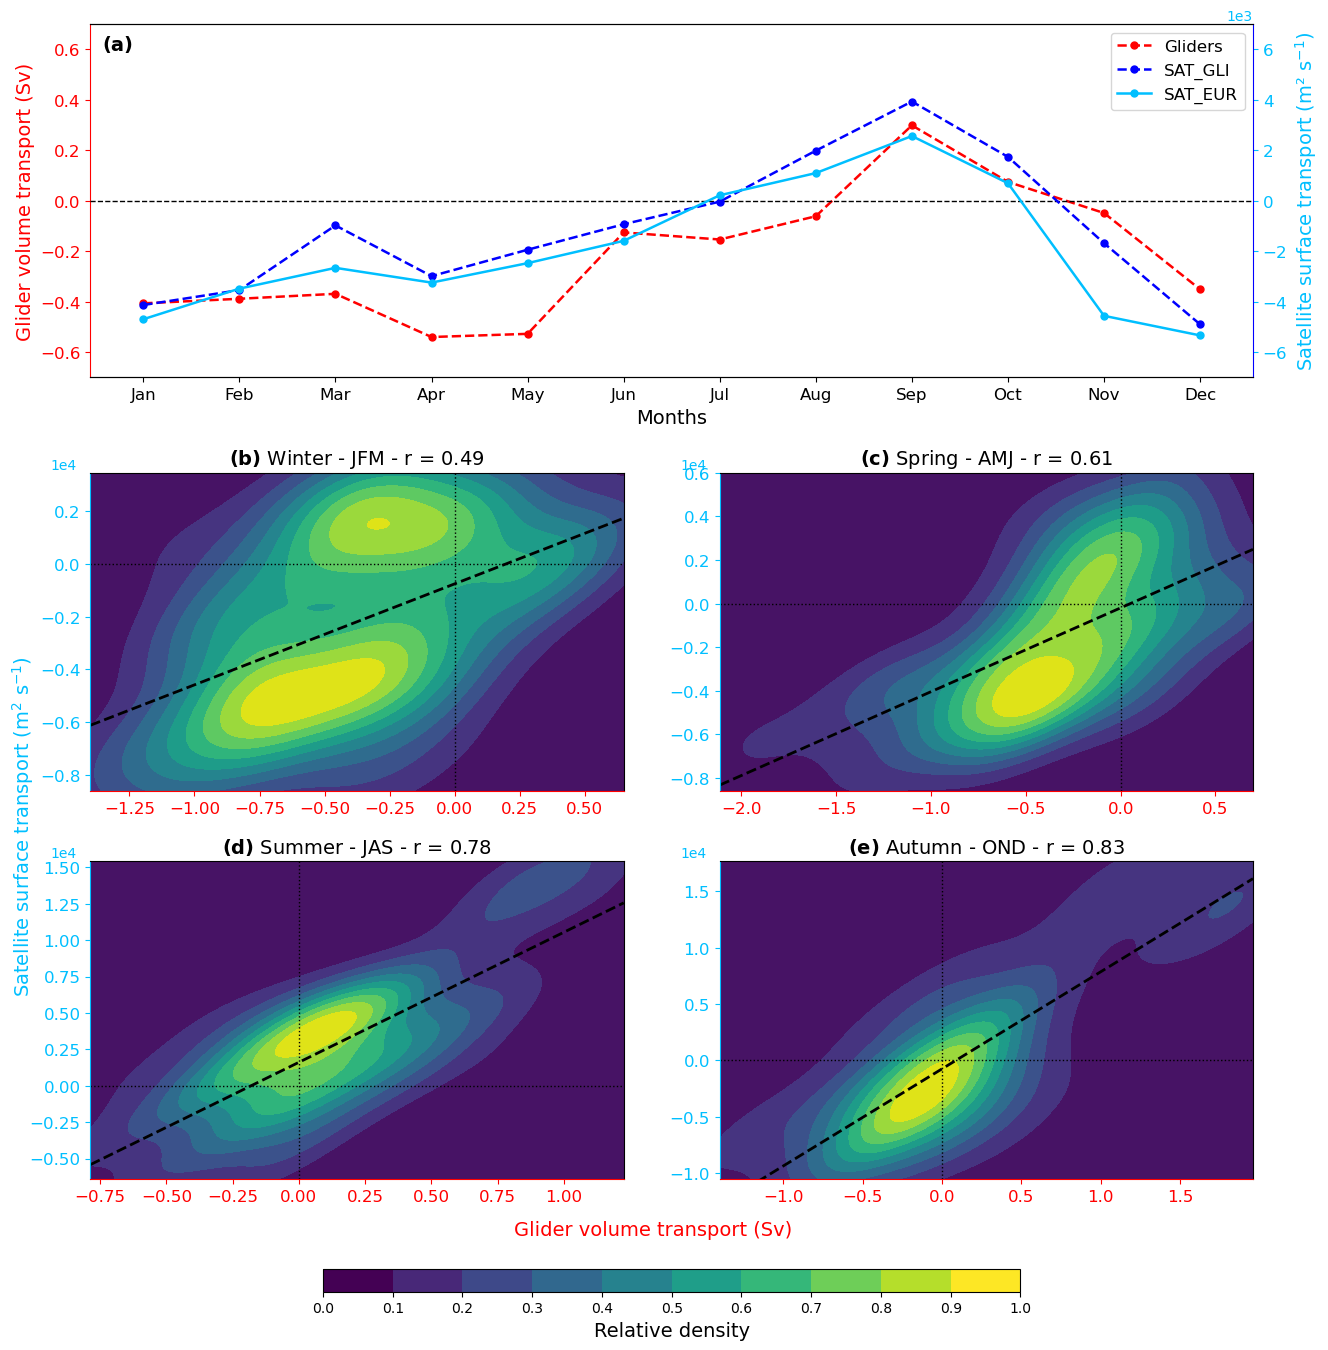

In [ ]:
months = np.arange(1, 13)

month_names = [calendar.month_abbr[m] for m in months]

colors = {"glider": "#FF0000", "sat": "#0000FF", "sat2": "#00BFFF"}

fig = plt.figure(figsize=(15, 15))

gs = gridspec.GridSpec(2, 1, height_ratios=[1, 2], hspace=0.18)

ax_left = fig.add_subplot(gs[0])
ax_right = ax_left.twinx()

ax_left.plot(
    months,
    climatologie_mensuelle_mean,
    color=colors["glider"],
    marker="o",
    linestyle="--",
    linewidth=1.8,
    markersize=5,
    label="Gliders",
)

ax_right.plot(
    months,
    climatologie_mensuelle_meansat,
    color=colors["sat"],
    marker="o",
    linestyle="--",
    linewidth=1.8,
    markersize=5,
    label="SAT_GLI",
    zorder=10,
)

ax_right.plot(
    months,
    climatologie_mensuelle_meansat2,
    color=colors["sat2"],
    marker="o",
    linestyle="-",
    linewidth=1.8,
    markersize=5,
    label="SAT_EUR",
    zorder=10,
)

ax_right.axhline(0, color="k", linewidth=1, linestyle="--", zorder=0)
ax_left.set_xticks(months)
ax_left.set_xticklabels(month_names, fontsize=12)
ax_left.set_xlabel("Months", fontsize=14)
ax_left.set_ylim(-0.7, 0.7)
ax_left.set_ylabel("Glider volume transport (Sv)", color=colors["glider"], fontsize=14)
ax_left.tick_params(axis="y", colors=colors["glider"], labelsize=12)
ax_left.spines["left"].set_color(colors["glider"])
ax_right.set_ylim(-7000, 7000)
ax_right.set_ylabel("Satellite surface transport (m² s$^{-1}$)", color=colors["sat2"], fontsize=14)
ax_right.tick_params(axis="y", colors=colors["sat2"], labelsize=12)
ax_right.spines["right"].set_color(colors["sat"])
ax_right.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
ax_left.spines["right"].set_visible(False)
ax_right.spines["left"].set_visible(False)

h_left, l_left = ax_left.get_legend_handles_labels()
h_right, l_right = ax_right.get_legend_handles_labels()

ax_left.legend(h_left + h_right, l_left + l_right, loc="upper right", fontsize=12)
ax_left.text(0.01, 0.97, "(a)", transform=ax_left.transAxes, fontsize=14, fontweight="bold", va="top")

subgs = gs[1].subgridspec(2, 2, wspace=0.18, hspace=0.22)

axs = np.array(
    [
        fig.add_subplot(subgs[0, 0]),
        fig.add_subplot(subgs[0, 1]),
        fig.add_subplot(subgs[1, 0]),
        fig.add_subplot(subgs[1, 1]),
    ]
)

x_total = gl_sel["northward_transport"] + gl_sel["southward_transport"]
x_total, y_sat = xr.align(x_total, transeurgl, join="inner")
x_total = x_total.rename("glider_total_transport")
y_sat = y_sat.rename("sat_surface_transport")

seasons = {
    "Winter - JFM": [1, 2, 3],
    "Spring - AMJ": [4, 5, 6],
    "Summer - JAS": [7, 8, 9],
    "Autumn - OND": [10, 11, 12],
}

z_list = []

for season_name, season_months in seasons.items():
    mask = x_total["time"].dt.month.isin(season_months)
    x_season = x_total.where(mask, drop=True)
    y_season = y_sat.where(mask, drop=True)
    x_season, y_season = xr.align(x_season, y_season, join="inner")
    valid = np.isfinite(x_season) & np.isfinite(y_season)
    x_np = x_season.where(valid, drop=True).values
    y_np = y_season.where(valid, drop=True).values
    if x_np.size < 3:
        continue
    xy = np.vstack([x_np, y_np])
    kde = gaussian_kde(xy)
    x_grid = np.linspace(x_np.min(), x_np.max(), 200)
    y_grid = np.linspace(y_np.min(), y_np.max(), 200)
    xx_grid, yy_grid = np.meshgrid(x_grid, y_grid)
    z = kde(np.vstack([xx_grid.ravel(), yy_grid.ravel()])).reshape(xx_grid.shape)
    z_list.append(z)

if len(z_list) == 0:
    raise ValueError("No valid seasonal data to plot.")

for i, (season_name, season_months) in enumerate(seasons.items()):
    ax = axs[i]
    mask = x_total["time"].dt.month.isin(season_months)
    x_season = x_total.where(mask, drop=True)
    y_season = y_sat.where(mask, drop=True)
    x_season, y_season = xr.align(x_season, y_season, join="inner")
    valid = np.isfinite(x_season) & np.isfinite(y_season)
    x_np = x_season.where(valid, drop=True).values
    y_np = y_season.where(valid, drop=True).values
    panel_letter = chr(ord("b") + i)
    if x_np.size < 3:
        ax.text(0.5, 0.5, f"{season_name}: insufficient data", ha="center", va="center")
        ax.set_axis_off()
        continue
    xy = np.vstack([x_np, y_np])
    kde = gaussian_kde(xy)
    x_grid = np.linspace(x_np.min(), x_np.max(), 200)
    y_grid = np.linspace(y_np.min(), y_np.max(), 200)
    xx_grid, yy_grid = np.meshgrid(x_grid, y_grid)
    z = kde(np.vstack([xx_grid.ravel(), yy_grid.ravel()])).reshape(xx_grid.shape)
    z_norm = z / z.max()
    ax.contourf(xx_grid, yy_grid, z_norm, levels=10, cmap=cm.viridis, vmin=0, vmax=1)
    corr = np.corrcoef(x_np, y_np)[0, 1]
    slope, intercept, *_ = linregress(x_np, y_np)
    xx = np.linspace(x_np.min(), x_np.max(), 100)
    yy = slope * xx + intercept
    ax.plot(xx, yy, "k--", linewidth=2)
    ax.set_title(rf"$\bf{{({panel_letter})}}$ " f"{season_name} - r = {corr:.2f}", fontsize=14)
    ax.tick_params(axis="both", which="major", labelsize=12)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(4, 4))
    offset_text = ax.yaxis.get_offset_text()
    offset_text.set_x(-0.025)
    offset_text.set_y(+0.01)
    offset_text.set_horizontalalignment("right")
    ax.set_xlim(x_np.min(), x_np.max())
    ax.set_ylim(y_np.min(), y_np.max())
    ax.axvline(0, color="k", linestyle=":", linewidth=1)
    ax.axhline(0, color="k", linestyle=":", linewidth=1)
    ax.spines["left"].set_color("#00BFFF")
    ax.tick_params(axis="y", colors="#00BFFF", labelsize=12)
    ax.spines["bottom"].set_color("#FF0000")
    ax.tick_params(axis="x", colors="#FF0000", labelsize=12)

fig.supxlabel("Glider volume transport (Sv)", fontsize=14, color="#FF0000", y=0.07)
fig.canvas.draw()
y0 = min(ax.get_position().y0 for ax in axs)
y1 = max(ax.get_position().y1 for ax in axs)
y_center = 0.5 * (y0 + y1)

fig.text(
    0.08,
    y_center,
    r"Satellite surface transport (m$^2$ s$^{-1}$)",
    rotation="vertical",
    va="center",
    ha="center",
    fontsize=14,
    color="#00BFFF",
)

levels = np.linspace(0, 1, 11)
cmap_kde = cm.get_cmap("viridis", 10)
norm_kde = mcolors.BoundaryNorm(levels, cmap_kde.N)
sm_kde = cm.ScalarMappable(norm=norm_kde, cmap=cmap_kde)
sm_kde.set_array([])
fig.canvas.draw()
x0 = min(ax.get_position().x0 for ax in axs)
x1 = max(ax.get_position().x1 for ax in axs)
y0 = min(ax.get_position().y0 for ax in axs)
cax_kde = fig.add_axes([x0 + 0.20 * (x1 - x0), y0 - 0.075, 0.60 * (x1 - x0), 0.015])
cbar_kde = fig.colorbar(sm_kde, cax=cax_kde, orientation="horizontal", ticks=levels)
cbar_kde.set_label("Relative density", fontsize=14, labelpad=4)

plt.savefig("../../figures/fig02.png", dpi=300, bbox_inches="tight")
plt.show()

## Fig. 3: Pearson correlation by season and water mass

The glider transport is split by water mass (AWr+AWm: Atlantic Water, WIW: Winter Intermediate Water,
LIW: Levantine Intermediate Water, WMDW: Western Mediterranean Deep Water) and compared with SAT_GLI.

In [ ]:
water_masses = {
    "All water masses": (gl_sel.northward_transport + gl_sel.southward_transport),
    "AWr+AWm": (
        gl_sel.northward_transport_AWr
        + gl_sel.southward_transport_AWr
        + gl_sel.northward_transport_AWm
        + gl_sel.southward_transport_AWm
    ),
    "WIW": (gl_sel.northward_transport_WIW + gl_sel.southward_transport_WIW),
    "LIW": (gl_sel.northward_transport_LIW + gl_sel.southward_transport_LIW),
    "WMDW": (gl_sel.northward_transport_WMDW + gl_sel.southward_transport_WMDW),
}

satellite = transeurgl

seasons = {
    "Total": np.arange(1, 13),
    "Winter": [1, 2, 3],
    "Spring": [4, 5, 6],
    "Summer": [7, 8, 9],
    "Autumn": [10, 11, 12],
}


def compute_correlation(glider, satellite):
    glider, satellite = xr.align(glider, satellite, join="inner")
    x = np.asarray(glider.values)
    y = np.asarray(satellite.values)
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]
    if len(x) < 3:
        return np.nan
    r, p = pearsonr(x, y)
    return r


correlations = []

for season_name, months in seasons.items():
    row = {}
    for wm_name, glider_transport in water_masses.items():
        glider_season = glider_transport.where(
            glider_transport["time"].dt.month.isin(months), drop=True)
        satellite_season = satellite.where(satellite["time"].dt.month.isin(months), drop=True)
        r = compute_correlation(glider_season, satellite_season)
        row[wm_name] = r
    correlations.append(row)

df_corr = pd.DataFrame(correlations, index=list(seasons.keys()))

/tmp/ipykernel_193326/377079799.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("RdBu_r")


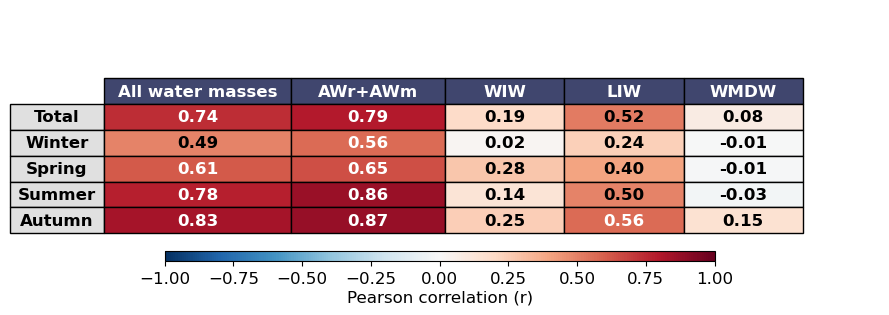

In [ ]:
fig = plt.figure(figsize=(11, 4))

gs = gridspec.GridSpec(2, 1, height_ratios=[5, 0.25], hspace=0.001)
ax = fig.add_subplot(gs[0])
cax = fig.add_subplot(gs[1])
ax.axis("off")
pos = cax.get_position()
cax.set_position([0.25, pos.y0 + 0.2, 0.5, 0.02])
columns = ["All water masses", "AWr+AWm", "WIW", "LIW", "WMDW"]
rows = ["Total", "Winter", "Spring", "Summer", "Autumn"]
cell_text = [
    [
        f"{df_corr.loc[row, col]:.2f}" if np.isfinite(df_corr.loc[row, col]) else ""
        for col in columns
    ]
    for row in rows
]

table = ax.table(
    cellText=cell_text,
    rowLabels=rows,
    colLabels=columns,
    cellLoc="center",
    rowLoc="center",
    loc="center",
    colWidths=[0.22, 0.18, 0.14, 0.14, 0.14],
)

table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.55)

cmap = cm.get_cmap("RdBu_r")
norm = Normalize(vmin=-1, vmax=1)

for col in range(len(columns)):
    cell = table[(0, col)]
    cell.set_facecolor("#40466e")
    cell.get_text().set_color("white")
    cell.get_text().set_weight("bold")

for row in range(1, len(rows) + 1):
    cell = table[(row, -1)]
    cell.set_facecolor("#e0e0e0")
    cell.get_text().set_weight("bold")

for i, row in enumerate(rows, start=1):
    for j, col in enumerate(columns):
        cell = table[(i, j)]
        value = df_corr.loc[row, col]
        if np.isfinite(value):
            cell.set_facecolor(cmap(norm(value)))
            if abs(value) > 0.55:
                cell.get_text().set_color("white")
            else:
                cell.get_text().set_color("black")
            cell.get_text().set_weight("bold")

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")

cbar.set_label("Pearson correlation (r)", fontsize=12, labelpad=3)
cbar.ax.tick_params(labelsize=12)
cax.set_position([0.25, 0.250, 0.50, 0.025])

plt.savefig("../../figures/fig03.png", dpi=300, bbox_inches="tight")
plt.show()

## Fig. 4: 2023-2024 time series and SWOT pass 348 after the DANA (29 October 2024)

SWOT L3 transport is computed along the line closest to 39$^\circ$N, one value per cycle.

In [11]:
l3 = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/SWOT_Ibiza/merged_by_pass/Science_L3v3_merged_348_20230802_20260902.nc')

# Transport of each SWOT cycle
swot = swot_section_transport(l3)
swot_time, swot_north, swot_south = swot['time'], swot['north'], swot['south']

# Time windows: from the first SWOT cycle to the last glider crossing
last_glider = glider.time.values[-1]
idx_glider = closest_index(glider.time.values, swot_time[0])
idx_eur = closest_index(transeur.time.values, swot_time[0])
idx_eur_end = closest_index(transeur.time.values, last_glider)
valid = ~pd.isna(swot_time)
n_swot = int(np.where(swot_time == swot_time[valid][closest_index(swot_time[valid], last_glider)])[0][0])
tgl = pd.to_datetime(glider.time[idx_glider:])

# First SWOT cycle after the DANA
cycle_start = l3.time.isel(num_lines=0)
l3_1 = l3.isel(cycle=int(np.where((cycle_start > pd.Timestamp('2024-10-29')).values)[0][0]))

/home/hargous/anaconda3/envs/paul_eke/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:509: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  return super().draw(renderer=renderer, **kwargs)


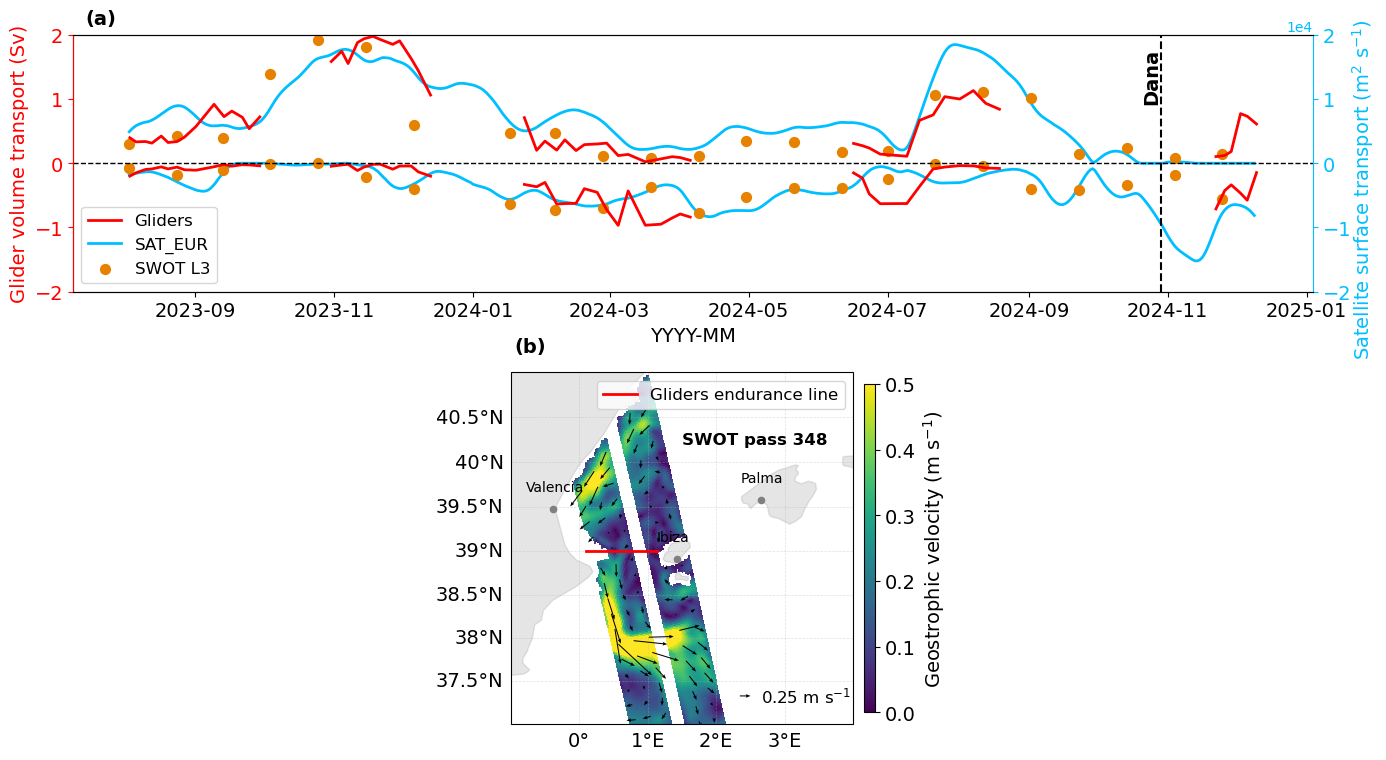

In [ ]:
fig = plt.figure(figsize=(16, 10))

gs = gridspec.GridSpec(2, 3, figure=fig, height_ratios=[1, 2], width_ratios=[1, 1, 1], hspace=0.0, wspace=0.2)
ax1 = fig.add_subplot(gs[0, :])
ax_inset = fig.add_subplot(gs[1, 1], projection=ccrs.Mercator())

plot_gliders(
    ax1,
    tgl,
    glider.northward_transport[idx_glider:],
    tgl,
    glider.southward_transport[idx_glider:],
    "#FF0000",
    "Gliders",
)

axx = ax1.twinx()

plot_gliders(
    axx,
    transeur_north.time[idx_eur:idx_eur_end],
    transeur_north[idx_eur:idx_eur_end],
    transeur_south.time[idx_eur:idx_eur_end],
    transeur_south[idx_eur:idx_eur_end],
    "#00BFFF",
    "SAT_EUR",
)

axx.scatter(swot_time[:n_swot], swot_south[:n_swot], color="#E68200", s=50, zorder=100)
axx.scatter(swot_time[:n_swot], swot_north[:n_swot], color="#E68200", s=50, zorder=100, label="SWOT L3")

ax1.axhline(0, color="k", lw=1, linestyle="--")
ax1.set_ylabel("Glider volume transport (Sv)", fontsize=14)

axx.set_ylabel(r"Satellite surface transport (m$^{2}$ s$^{-1}$)", fontsize=14)
axx.yaxis.set_label_coords(1.03, 0.4)
axx.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))

axx.set_zorder(0)
ax1.set_zorder(1)
ax1.patch.set_visible(False)
ax1.spines["left"].set_color("#FF0000")
ax1.yaxis.label.set_color("#FF0000")
ax1.tick_params(axis="y", colors="#FF0000", labelsize=14)
ax1.spines["right"].set_color("none")
axx.spines["right"].set_color("#00BFFF")
axx.yaxis.label.set_color("#00BFFF")
axx.tick_params(axis="y", colors="#00BFFF", labelsize=14)
ax1.tick_params(axis="x", labelsize=14)
ax1.set_xlabel("YYYY-MM", fontsize=14)
ax1.set_ylim(-2, 2)
axx.set_ylim(-20000, 20000)
lines_ax1, labels_ax1 = ax1.get_legend_handles_labels()
lines_axx, labels_axx = axx.get_legend_handles_labels()
ax1.legend(lines_ax1 + lines_axx, labels_ax1 + labels_axx, fontsize=12)

lonmin, lonmax, latmin, latmax = -1, 4, 37, 41

ax_inset.set_extent([lonmin, lonmax, latmin, latmax], crs=ccrs.PlateCarree())
l3_11 = l3_1.where(l3_1.quality_flag < 26)
u = l3_11.ugos_filtered.values
v = l3_11.vgos_filtered.values
velocity_magnitude = np.sqrt(u**2 + v**2)

pcm = ax_inset.pcolormesh(
    l3_11.lon,
    l3_11.lat,
    velocity_magnitude,
    cmap="viridis",
    transform=ccrs.PlateCarree(),
    vmin=0,
    vmax=0.5,
    shading="auto",
)

cbar = fig.colorbar(pcm, ax=ax_inset, orientation="vertical", fraction=0.03, pad=0.03, aspect=30)
cbar.set_label(r"Geostrophic velocity (m s$^{-1}$)", fontsize=14)
cbar.ax.tick_params(labelsize=14)

step = 10

lon_q = l3_11.lon.values[::step, ::step]
lat_q = l3_11.lat.values[::step, ::step]
u_q = u[::step, ::step]
v_q = v[::step, ::step]

q = ax_inset.quiver(
    lon_q,
    lat_q,
    u_q,
    v_q,
    transform=ccrs.PlateCarree(),
    color="black",
    scale=8,
    width=0.003,
    headwidth=3.5,
    headlength=4.5,
    headaxislength=4,
    zorder=5,
)

ax_inset.quiverkey(
    q,
    X=0.7,
    Y=0.08,
    U=0.25,
    label=r"0.25 m s$^{-1}$",
    labelpos="E",
    coordinates="axes",
    fontproperties={"size": 12},
)

ax_inset.text(
    1.5,
    40.25,
    "SWOT pass 348",
    color="black",
    fontsize=12,
    fontweight="bold",
    transform=ccrs.PlateCarree(),
    va="center",
)

ax_inset.plot(
    [0.1, 1.13],
    [39, 39],
    color="red",
    linewidth=2,
    transform=ccrs.PlateCarree(),
    label="Gliders endurance line",
    zorder=10,
)

ax_inset.legend(fontsize=12)
land = feature.NaturalEarthFeature("physical", "land", "50m", edgecolor="grey", facecolor="grey", alpha=0.2, zorder=1)
ax_inset.add_feature(land)
ax_inset.scatter(location.longitude, location.latitude, s=20, transform=ccrs.PlateCarree(), c="grey", zorder=100)

ax_inset.text(
    location.longitude - 0.4,
    location.latitude + 0.2,
    "Valencia",
    transform=ccrs.PlateCarree(),
    fontsize=10,
)

ax_inset.scatter(
    location2.longitude,
    location2.latitude,
    s=20,
    transform=ccrs.PlateCarree(),
    c="grey",
    zorder=100,
)

ax_inset.text(
    location2.longitude - 0.3,
    location2.latitude + 0.2,
    "Palma",
    transform=ccrs.PlateCarree(),
    fontsize=10,
)

ax_inset.scatter(
    location3.longitude,
    location3.latitude,
    s=20,
    transform=ccrs.PlateCarree(),
    c="grey",
    zorder=100,
)

ax_inset.text(
    location3.longitude - 0.3,
    location3.latitude + 0.2,
    "Ibiza",
    transform=ccrs.PlateCarree(),
    fontsize=10,
)

gl = ax_inset.gridlines(draw_labels=True, linestyle="--", alpha=0.4, linewidth=0.5)

gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
date_dana = pd.Timestamp("2024-10-29")
ax1.axvline(date_dana, color="k", linestyle="--", linewidth=1.5, zorder=10)

ax1.text(
    date_dana,
    0.95,
    "Dana",
    transform=ax1.get_xaxis_transform(),
    rotation=90,
    va="top",
    ha="right",
    fontsize=14,
    fontweight="bold",
    color="k",
)

ax1.text(0.01, 1.1, "(a)", transform=ax1.transAxes, fontsize=14, fontweight="bold", va="top")
ax_inset.text(0.01, 1.1, "(b)", transform=ax_inset.transAxes, fontsize=14, fontweight="bold", va="top")

plt.savefig("../../figures/fig04.png", dpi=300, bbox_inches="tight")
plt.show()

---
# Supporting Information

## Fig. S1: mean dynamic topography around the glider line

In [13]:
a = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/mdt/mdt_cmems_2020_med.nc')
a = a.rename({'longitude': 'lon', 'latitude': 'lat'})
a = a.sel(lat=slice(38, 40), lon=slice(-0.5, 2))

b = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/mdt/SMDT-MED-2014.nc')
b = b.rename({'longitude': 'lon', 'latitude': 'lat'})
b = b.sel(lat=slice(38, 40), lon=slice(-0.5, 2))

# MedMFC mean sea surface, 2011-2025
modmdtadt = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/model_006_004/cmems_mod_med_adt2d.nc')
modmdtadt = modmdtadt.rename({'longitude': 'lon', 'latitude': 'lat'})
modmdtadt = modmdtadt.sel(lat=slice(38, 40), lon=slice(-0.5, 2))
zos_mean2 = modmdtadt.zos.mean(dim='time')

/tmp/ipykernel_193326/2383876571.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


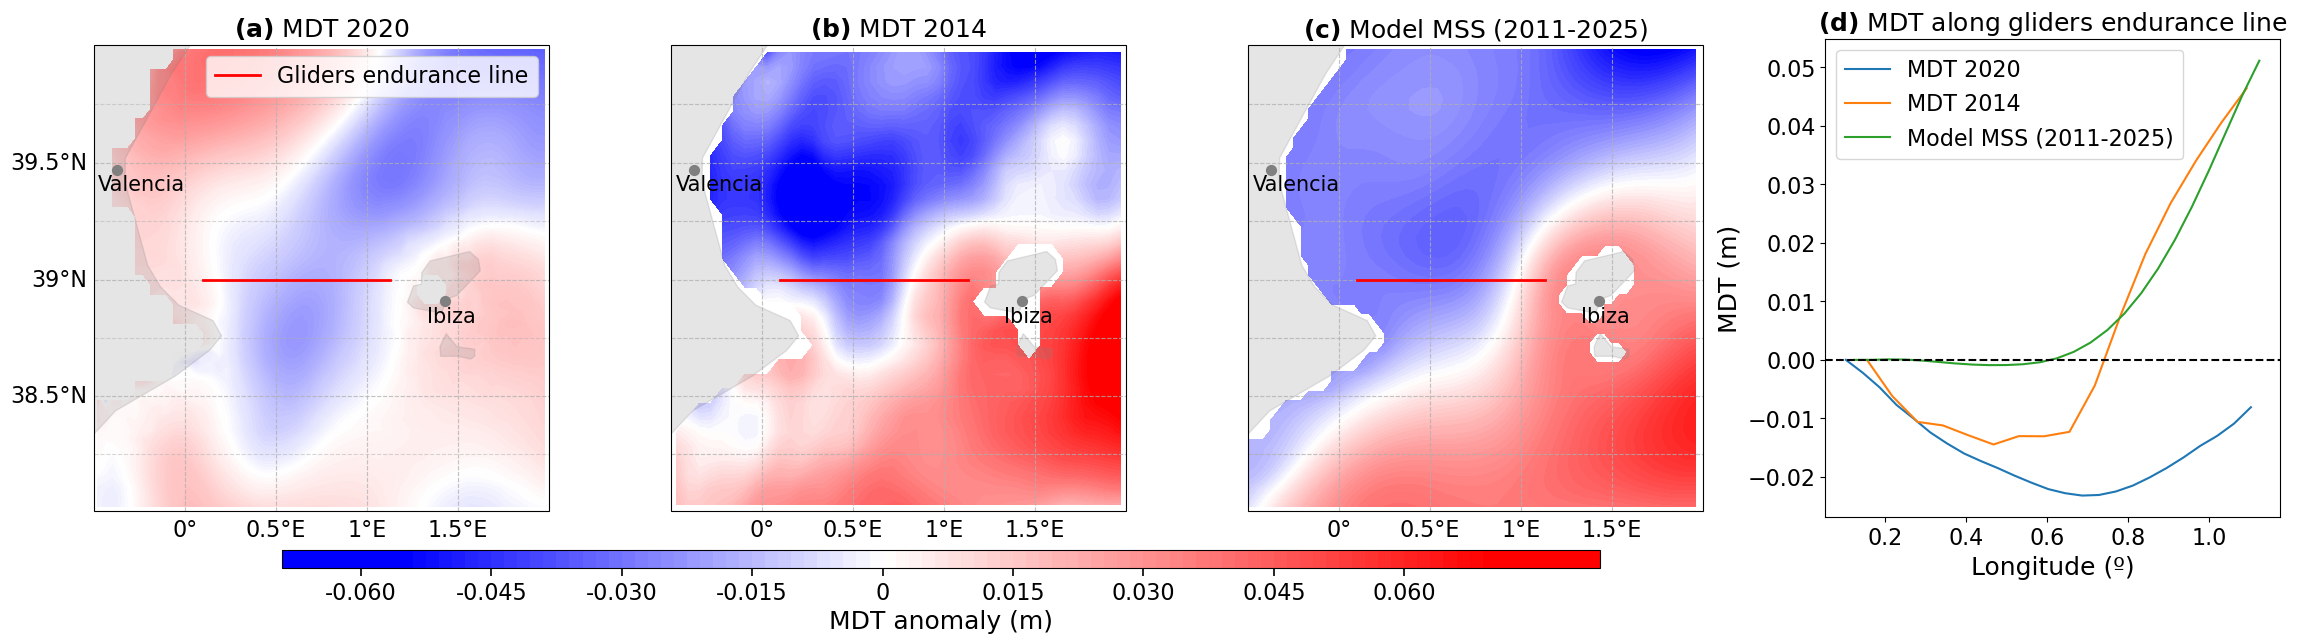

In [ ]:
fig = plt.figure(figsize=(23, 6))
gs = gridspec.GridSpec(1, 4, width_ratios=[1, 1, 1, 1], figure=fig)

ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.Mercator())
ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.Mercator())
ax3 = fig.add_subplot(gs[0, 2], projection=ccrs.Mercator())

axes_map = [ax1, ax2, ax3]

for ax in axes_map:
    ax.set_extent([-0.5, 2, 38, 40], crs=ccrs.PlateCarree())
    ax.add_feature(feature.NaturalEarthFeature("physical", "land", "50m", edgecolor="grey", facecolor="grey", alpha=0.2))
    ax.gridlines(draw_labels=False, linestyle="--", alpha=0.5)
    ax.plot(
        [0.1, 1.13],
        [39, 39],
        color="red",
        linewidth=2,
        transform=ccrs.PlateCarree(),
        zorder=100,
        label="Gliders endurance line",
    )

mdtA = a.mdt[0, :, :] - a.mdt[0, :, :].mean()
mdtB = b.MDT[:, :] - b.MDT[:, :].mean()
mdtD = zos_mean2 - zos_mean2.mean()

m1 = ax1.contourf(
    a.lon,
    a.lat,
    mdtA,
    levels=100,
    cmap="bwr",
    norm=TwoSlopeNorm(vmin=-0.055, vcenter=0, vmax=0.07),
    transform=ccrs.PlateCarree(),
)
ax1.set_title(r"$\mathbf{(a)}$ MDT 2020", fontsize=18)
gl1 = ax1.gridlines(draw_labels=True, linestyle="--", alpha=0.5)
gl1.top_labels = False
gl1.right_labels = False
gl1.xlabel_style = {"size": 16}
gl1.ylabel_style = {"size": 16}
gl1.ylocator = mticker.MultipleLocator(0.5)
ax1.legend(fontsize=16)

m2 = ax2.contourf(
    b.lon,
    b.lat,
    mdtB,
    levels=100,
    cmap="bwr",
    norm=TwoSlopeNorm(vmin=-0.055, vcenter=0, vmax=0.07),
    transform=ccrs.PlateCarree(),
)
ax2.set_title(r"$\mathbf{(b)}$ MDT 2014", fontsize=18)
gl2 = ax2.gridlines(draw_labels=True, linestyle="--", alpha=0.5)
gl2.top_labels = False
gl2.right_labels = False
gl2.left_labels = False
gl2.xlabel_style = {"size": 16}
gl2.ylabel_style = {"size": 16}

m3 = ax3.contourf(
    zos_mean2.lon,
    zos_mean2.lat,
    mdtD,
    levels=100,
    cmap="bwr",
    norm=TwoSlopeNorm(vmin=-0.055, vcenter=0, vmax=0.07),
    transform=ccrs.PlateCarree(),
)

ax3.set_title(r"$\mathbf{(c)}$ Model MSS (2011-2025)", fontsize=18)
gl3 = ax3.gridlines(draw_labels=True, linestyle="--", alpha=0.5)
gl3.top_labels = False
gl3.right_labels = False
gl3.left_labels = False
gl3.xlabel_style = {"size": 16}
gl3.ylabel_style = {"size": 16}

pos1 = ax1.get_position()
pos3 = ax3.get_position()

cbar_ax = fig.add_axes([pos1.x0, pos1.y0 - 0.12, pos3.x1 - pos1.x0, 0.03])

ticks = np.arange(-0.060, 0.060 + 0.015, 0.015)
ticks = np.unique(np.append(ticks, 0))
ticks = np.sort(ticks)

cbar = fig.colorbar(m2, cax=cbar_ax, orientation="horizontal")
cbar.set_ticks(ticks[:-1])
cbar.set_label("MDT anomaly (m)", fontsize=18)
cbar.ax.tick_params(labelsize=16, length=6, width=1.2)
labels = ["0" if abs(t) < 1e-6 else f"{t:.3f}" for t in ticks]
cbar.set_ticklabels(labels[:-1])

ax4 = fig.add_subplot(gs[0, 3])

acanales = a.sel(lat=39, method="nearest").sel(lon=slice(0.1, 1.13)).mdt
bcanales = b.sel(lat=39, method="nearest").sel(lon=slice(0.1, 1.13)).MDT
dcanales = zos_mean2.sel(lat=39, method="nearest").sel(lon=slice(0.1, 1.13))

ax4.plot(acanales.lon, acanales[0, :] - acanales[0, 0], label="MDT 2020")
ax4.plot(bcanales.lon, bcanales[:] - bcanales[0], label="MDT 2014")

ax4.plot(dcanales.lon, dcanales - dcanales[0], label="Model MSS (2011-2025)")

ax4.axhline(0, color="black", linestyle="--")
ax4.set_xlabel("Longitude (º)", fontsize=18)
ax4.set_ylabel("MDT (m)", fontsize=18)
ax4.set_title(r"$\mathbf{(d)}$ MDT along gliders endurance line", fontsize=18)
ax4.legend(fontsize=16)
ax4.tick_params(axis="both", labelsize=16)
for ax in [ax1, ax2, ax3]:
    ax.scatter(
        location.longitude,
        location.latitude,
        s=50,
        transform=ccrs.PlateCarree(),
        c="grey",
        zorder=100,
    )
    ax.text(
        location.longitude - 0.1,
        location.latitude - 0.09,
        "Valencia",
        transform=ccrs.PlateCarree(),
        fontsize=15,
    )
    ax.scatter(
        location3.longitude,
        location3.latitude,
        s=50,
        transform=ccrs.PlateCarree(),
        c="grey",
        zorder=100,
    )
    ax.text(
        location3.longitude - 0.1,
        location3.latitude - 0.09,
        "Ibiza",
        transform=ccrs.PlateCarree(),
        fontsize=15,
    )

plt.tight_layout()
plt.savefig("../../figures/figS1.png", dpi=300, bbox_inches="tight")
plt.show()

## Fig. S2: all altimetry products and the MedMFC model

Products: SAT_EUR (regional L4), SAT_GLO (global L4, 1/8$^\circ$), SAT_TWO (two-satellite reference, 1/4$^\circ$),
SAT_KARIN (nadir altimeters + SWOT KaRIn, from 2023), and SWOT L3.

In [15]:
# SAT_TWO
dstwo = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/twoglo_phy_008_057/dt_glo_phy_ssh_twosat_01012011_01052025.nc')
masktwo = xr.open_dataset('../../results/mask/WMED_GIBR_twoglo.nc')
dstwo = dstwo.where(masktwo["mask"], drop=True)
a = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/twoglo_phy_008_057/dt_glo_phy_ssh_twosat_02052025_16012026.nc')
a = a.rename({'longitude': 'lon', 'latitude': 'lat'})
a = a.where(masktwo["mask"], drop=True)
dstwo = xr.concat([dstwo, a], dim="time")

# SAT_GLO
dsglo = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/glo_phy_008_047/dt_glo_phy_ssh_allsat_01012011_01052025.nc')
maskglo = xr.open_dataset('../../results/mask/WMED_GIBR_glo.nc')
dsglo = dsglo.where(maskglo["mask"], drop=True)
a = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/glo_phy_008_047/dt_glo_phy_ssh_allsat_02052025_18102025.nc')
b = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/glo_phy_008_047/dt_glo_phy_ssh_allsat_19102025_16012026.nc')
ab = xr.concat([a, b], dim="time")
ab = ab.rename({'longitude': 'lon', 'latitude': 'lat'})
ab = ab.where(maskglo["mask"], drop=True)
dsglo = xr.concat([dsglo, ab], dim="time")

# SAT_KARIN
dskar = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/L4_nadir_karin/L4_nadir_karin_merged.nc')
dskar = dskar.rename({'longitude': 'lon', 'latitude': 'lat'})

In [16]:
# Surface transports (m2 s-1)
dstwo39 = section_at_39N(dstwo)
dsglo39 = section_at_39N_global(dsglo)
dskar39 = section_at_39N(dskar)
transtwo, transtwo_north, transtwo_south = zonal_transport(dstwo39.vgos)
transglo, transglo_north, transglo_south = zonal_transport(dsglo39.vgos)
transkar, transkar_north, transkar_south = zonal_transport(dskar39.vgos)

# Climatologies of the products sampled at the glider times (2011-2022)
climatologie_mensuelle_meansattwo = monthly_climatology(
    transtwo_north.interp(time=gl_sel.time), transtwo_south.interp(time=gl_sel.time), CLIM_END)
climatologie_mensuelle_meansatglo = monthly_climatology(
    transglo_north.interp(time=gl_sel.time), transglo_south.interp(time=gl_sel.time), CLIM_END)

SAT_GLO with the MDT of CNES-CLS18: the geostrophic velocity of SAT_GLO is corrected for the difference between the
MDT of the product and the CNES-CLS18 MDT (interpolated on the section).

In [ ]:
# MDT CNES-CLS18 (global)
mdt18 = xr.open_dataset("/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/mdt/mdt_cnes_cls18_global.nc")
mdt18 = mdt18.rename({"longitude": "lon", "latitude": "lat"})
mdt18 = mdt18.assign_coords(lon=((mdt18.lon + 180) % 360) - 180)
mdt18 = mdt18.sortby(mdt18.lon)
mdt18 = mdt18.sel(lat=slice(38, 40), lon=slice(-0.5, 2))

mdt18_39 = (
    xr.concat(
        [
            mdt18.sel(lon=slice(0.1, 1.13)),
            mdt18.interp(lon=[0.1, 1.13], kwargs={"fill_value": "extrapolate"}),
        ],
        dim="lon",
    )
    .sortby("lon")
    .interp(lat=39)
)

R = 6371000
g = 9.81
omega = 2 * np.pi / 86164
lat = dsglo39["lat"]
lat_rad = np.deg2rad(lat)
f = 2 * omega * np.sin(lat_rad)

dmdt = dsglo39.adt[0, :] - dsglo39.sla[0, :] + 0.1 - mdt18_39["mdt"][0, :] #adjustements between the different products (MDT CNES-CLS18, SLA GLO and ADT GLO)
dx = R * np.cos(lat_rad) * (np.deg2rad(dsglo39.lon)).diff("lon")
dmdt_dx = dmdt / dx
v_new = dsglo39["vgos"] - g / f * dmdt_dx

phi = np.deg2rad(39)
R = 6371000
lon = dsglo39.lon.values
dx = np.gradient(np.deg2rad(lon)) * R * np.cos(phi)
dx_2d = xr.DataArray(dx, coords=[dsglo39.lon], dims=["lon"])
trans18 = (v_new * dx_2d).sum(dim="lon")

vgos_north = v_new.where(v_new > 0)
vgos_south = v_new.where(v_new < 0)
trans18_north = (vgos_north * dx_2d).sum(dim="lon")
trans18_south = (vgos_south * dx_2d).sum(dim="lon")

trans18north_gl = trans18_north.interp(time=gl_sel.time)
trans18south_gl = trans18_south.interp(time=gl_sel.time)
climatologie_mensuelle_meansat18 = monthly_climatology(trans18north_gl, trans18south_gl, CLIM_END)

/tmp/ipykernel_193326/4013021936.py:11: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  xr.concat(


MedMFC model along 39$^\circ$N.
* **Model 2D**: geostrophic surface velocity from the model sea surface height.
* **Model 3D**: model meridional velocity `vo` integrated over the whole section (Sv).

The model climatologies cover 2011-2024; the satellite climatologies above cover 2011-2022.

In [18]:
modadt = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/model_006_004/cmems_mod_med_adt_01012011_16012026.nc')
modv = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/model_006_004/cmems_mod_med_northcurr_01012011_16012026.nc')
modsal = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/model_006_004/cmems_mod_med_sal_01012011_16012026.nc')
modtemp = xr.open_dataset('/media/hargous/MyPassport/OT_Ibiza/data/CMEMS/model_006_004/cmems_mod_med_t_01012011_16012026.nc')

mod = xr.merge([modadt['zos'].rename('adt'), modv['vo'], modsal['so'], modtemp['thetao']])
mod = mod.rename({'longitude': 'lon', 'latitude': 'lat'})
mod = mod.squeeze(dim='lat')

In [19]:
# Section geometry: widths (m) and cell areas (m2)
phi = np.deg2rad(mod.lat.values)
f = 2 * OMEGA * np.sin(phi)
dx = np.gradient(np.deg2rad(mod.lon.values)) * R_EARTH * np.cos(phi)
dx_2d = xr.DataArray(dx, coords=[mod.lon], dims=['lon'])
dz_da = xr.DataArray(np.gradient(mod.depth.values), coords=[mod.depth], dims=['depth'])
area = dx_2d * dz_da

# Model 2D: surface geostrophic velocity from the sea surface height gradient
mod['vgeo'] = (('time', 'lon'), GRAVITY / f * np.gradient(mod.adt, axis=1) / dx)
transmod_north = (mod.vgeo.where(mod.vgeo > 0) * dx_2d).sum(dim='lon')
transmod_south = (mod.vgeo.where(mod.vgeo < 0) * dx_2d).sum(dim='lon')

# Model 3D: meridional velocity integrated over depth and longitude (Sv)
transmod3d_north = (mod.vo.where(mod.vo > 0) * area).sum(dim=['depth', 'lon']) / 1e6
transmod3d_south = (mod.vo.where(mod.vo < 0) * area).sum(dim=['depth', 'lon']) / 1e6

MODEL_CLIM_END = '2024-12-31'
climatologie_mensuelle_meanmod = monthly_climatology(
    transmod_north.interp(time=gl_sel.time), transmod_south.interp(time=gl_sel.time), MODEL_CLIM_END)
climatologie_mensuelle_meanmod3d = monthly_climatology(
    transmod3d_north.interp(time=gl_sel.time), transmod3d_south.interp(time=gl_sel.time), MODEL_CLIM_END)

/tmp/ipykernel_193326/2156126935.py:272: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


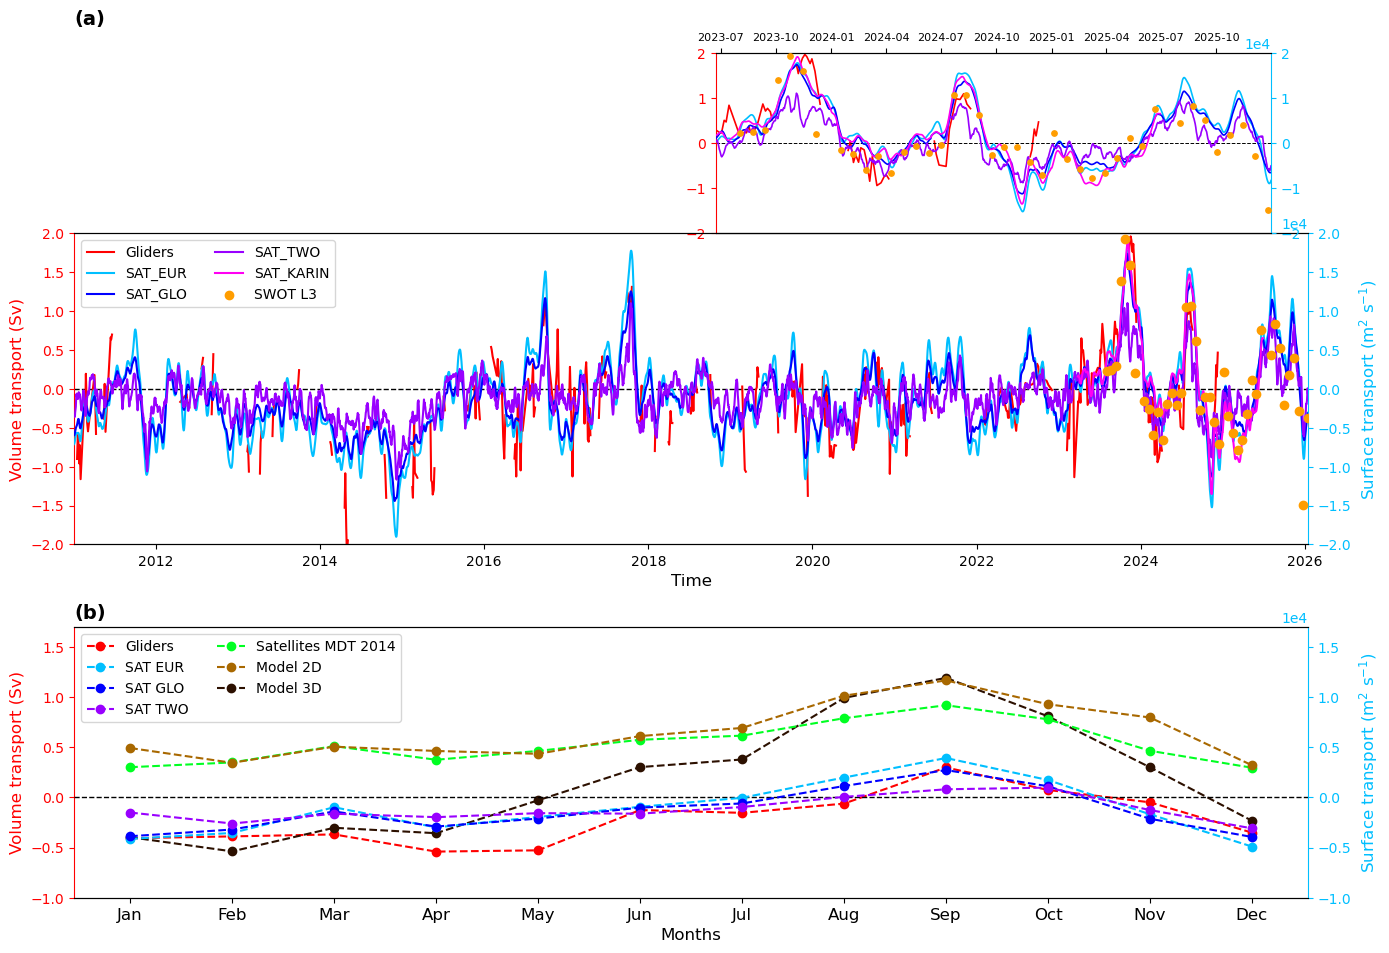

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={"height_ratios": [1.15, 1]}, sharex=False)

ax1 = axes[0]
ax2 = axes[1]

ax1.axhline(0, color="k", linestyle="--", linewidth=1)
dt = np.diff(glider.time.values)
gap = dt > np.timedelta64(30, "D")
data = glidernet.astype(float)
data[1:][gap] = np.nan
ax1.plot(glider.time, data, color="#FF0000", label="Gliders")
ax1.set_ylim(-2, 2)
ax1.set_ylabel("Volume transport (Sv)", color="#FF0000", fontsize=12)
ax1_twin = ax1.twinx()
ax1_twin.plot(transeur.time, transeur, color="#00BFFF", label="SAT_EUR")
ax1_twin.plot(transglo.time, transglo, color="#0000FF", label="SAT_GLO")
ax1_twin.plot(transtwo.time, transtwo, color="#9900FF", label="SAT_TWO")
ax1_twin.plot(transkar.time, transkar, color="#FF00F2", label="SAT_KARIN")
ax1_twin.scatter(swot_time, swot_south + swot_north, color="#FF9D00", label="SWOT L3", zorder=5)
ax1_twin.set_ylim(-20000, 20000)
ax1_twin.set_ylabel(r"Surface transport (m$^{2}$ s$^{-1}$)", color="#00BFFF", fontsize=12)
ax1_twin.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
ax1.set_xlim(np.datetime64("2011-01-01"), np.datetime64("2026-01-16"))
ax1.set_xlabel("Time", fontsize=12)
ax1.spines["left"].set_color("#FF0000")
ax1.yaxis.label.set_color("#FF0000")
ax1.tick_params(axis="y", colors="#FF0000")
ax1.spines["right"].set_visible(False)
ax1_twin.spines["right"].set_color("#00BFFF")
ax1_twin.yaxis.label.set_color("#00BFFF")
ax1_twin.tick_params(axis="y", colors="#00BFFF")
ax1_twin.spines["left"].set_visible(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=10, loc="upper left", ncol=2)
ax1.set_title("(a)", fontsize=14, fontweight="bold", loc="left")
ax2_left = ax2
ax2_right = ax2_left.twinx()

months = np.arange(1, 13)

month_names = [calendar.month_abbr[m] for m in months]

colors = {
    "glider": "#FF0000",
    "satglo": "#0000FF",
    "sateur": "#00BFFF",
    "sat18": "#00FF22",
    "satkar": "#00710F",
    "sattwo": "#9900FF",
    "mod2d": "#A86800",
    "mod3d": "#2C1000",
}

climatologie_mensuelle_mean_glider_on_sat = climatologie_mensuelle_mean

ax2_left.plot(
    months,
    climatologie_mensuelle_mean_glider_on_sat,
    color=colors["glider"],
    marker="o",
    linestyle="--",
    label="Gliders",
)

ax2_right.plot(
    months,
    climatologie_mensuelle_meansat,
    color=colors["sateur"],
    marker="o",
    linestyle="--",
    label="SAT EUR",
    zorder=10,
)

ax2_right.plot(
    months,
    climatologie_mensuelle_meansatglo,
    color=colors["satglo"],
    marker="o",
    linestyle="--",
    label="SAT GLO",
    zorder=10,
)

ax2_right.plot(
    months,
    climatologie_mensuelle_meansattwo,
    color=colors["sattwo"],
    marker="o",
    linestyle="--",
    label="SAT TWO",
    zorder=10,
)

ax2_right.plot(
    months,
    climatologie_mensuelle_meansat18,
    color=colors["sat18"],
    marker="o",
    linestyle="--",
    label="Satellites MDT 2014",
    zorder=10,
)

ax2_right.plot(
    months,
    climatologie_mensuelle_meanmod,
    color=colors["mod2d"],
    marker="o",
    linestyle="--",
    label="Model 2D",
    zorder=10,
)

climatologie_mensuelle_mean_model3d_on_sat = climatologie_mensuelle_meanmod3d

ax2_left.plot(
    months,
    climatologie_mensuelle_mean_model3d_on_sat,
    color=colors["mod3d"],
    marker="o",
    linestyle="--",
    label="Model 3D",
)

ax2_left.set_xticks(months)
ax2_left.set_xticklabels(month_names, fontsize=12)
ax2_left.set_xlabel("Months", fontsize=12)
ax2_right.axhline(0, color="k", linewidth=1.0, linestyle="--")
ax2_left.set_ylim(-1, 1.7)
ax2_right.set_ylim(-10000, 17000)
ax2_left.set_ylabel("Volume transport (Sv)", color="#FF0000", fontsize=12)
ax2_right.set_ylabel(r"Surface transport (m$^{2}$ s$^{-1}$)", color="#00BFFF", fontsize=12)
ax2_right.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
ax2_left.tick_params(axis="y", colors="#FF0000", labelsize=10)
ax2_right.tick_params(axis="y", colors="#00BFFF", labelsize=10)
ax2_left.spines["left"].set_color("#FF0000")
ax2_right.spines["right"].set_color("#00BFFF")

ax2_left.spines["right"].set_visible(False)
ax2_right.spines["left"].set_visible(False)

h1, l1 = ax2_left.get_legend_handles_labels()
h2, l2 = ax2_right.get_legend_handles_labels()
handle_dict = dict(zip(l1 + l2, h1 + h2))

ordered_labels = [
    "Gliders",
    "SAT EUR",
    "SAT GLO",
    "SAT TWO",
    "Satellites MDT 2014",
    "Model 2D",
    "Model 3D",
]

ordered_handles = [handle_dict[l] for l in ordered_labels]
ax2_left.legend(ordered_handles, ordered_labels, ncol=2, loc="upper left", fontsize=10)
ax2_left.set_title("(b)", fontsize=14, fontweight="bold", loc="left")
axins = ax1.inset_axes([0.52, 1, 0.45, 0.58])
axins_twin = axins.twinx()
zoom_start = np.datetime64("2023-06-23")
zoom_end = np.datetime64("2025-12-31")
axins.set_xlim(zoom_start, zoom_end)
mask_glider = (glider.time.values >= zoom_start) & (glider.time.values <= zoom_end)
axins.plot(glider.time.values[mask_glider], data[mask_glider], color="#FF0000", linewidth=1.2)
mask_sateur = (transeur.time.values >= zoom_start) & (transeur.time.values <= zoom_end)
axins_twin.plot(transeur.time.values[mask_sateur], transeur.values[mask_sateur], color="#00BFFF", linewidth=1.2)
mask_satglo = (transglo.time.values >= zoom_start) & (transglo.time.values <= zoom_end)
axins_twin.plot(transglo.time.values[mask_satglo], transglo.values[mask_satglo], color="#0000FF", linewidth=1.2)
mask_sattwo = (transtwo.time.values >= zoom_start) & (transtwo.time.values <= zoom_end)
axins_twin.plot(transtwo.time.values[mask_sattwo], transtwo.values[mask_sattwo], color="#9900FF", linewidth=1.2)
mask_satkar = (transkar.time.values >= zoom_start) & (transkar.time.values <= zoom_end)
axins_twin.plot(transkar.time.values[mask_satkar], transkar.values[mask_satkar], color="#FF00F2", linewidth=1.2)
swot_time = np.asarray(swot_time)
swot_transport = np.asarray(swot_south) + np.asarray(swot_north)
mask_swot = (swot_time >= zoom_start) & (swot_time <= zoom_end)

axins_twin.scatter(swot_time[mask_swot], swot_transport[mask_swot], color="#FF9D00", s=15, zorder=5)
axins.axhline(0, color="k", linestyle="--", linewidth=0.7)
axins.set_ylim(-2, 2)
axins_twin.set_ylim(-20000, 20000)
axins.tick_params(axis="x", which="both", top=True, labeltop=True, bottom=False, labelbottom=False, labelsize=8)
axins_twin.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
axins.tick_params(axis="y", colors="#FF0000", labelsize=10)
axins_twin.tick_params(axis="y", colors="#00BFFF", labelsize=10)
axins.spines["left"].set_color("#FF0000")
axins_twin.spines["right"].set_color("#00BFFF")
axins.spines["right"].set_visible(False)
axins_twin.spines["left"].set_visible(False)

plt.tight_layout()

plt.savefig("../../figures/figS2.png", dpi=300, bbox_inches="tight")
plt.show()

## Fig. S3: Lomb-Scargle spectra

The power is normalised by the variance of each series (dimensionless). It compares the shape of the spectra, not their energy.

In [21]:
freq_g, power_g = lomb_scargle_spectrum(glidernet)
freq_tg, power_tg = lomb_scargle_spectrum(transeurgl)
freq_t, power_t = lomb_scargle_spectrum(transeur)

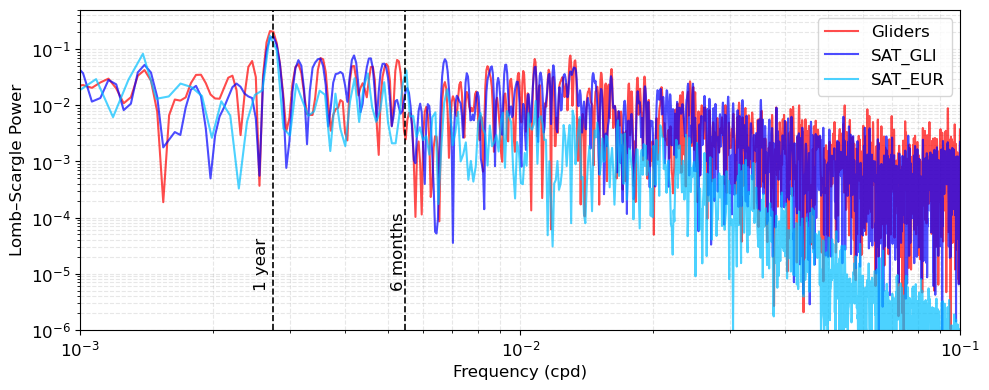

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.loglog(freq_g, power_g, color="#FF0000", alpha=0.7, label="Gliders")
ax.loglog(freq_tg, power_tg, color="#0000FF", alpha=0.7, label="SAT_GLI")
ax.loglog(freq_t, power_t, color="#00BFFF", alpha=0.7, label="SAT_EUR")
fx = 1 / 365.0
ax.axvline(fx, color="k", linestyle="--", linewidth=1.2)
ax.text(fx - 0.25e-3, 5e-6, "1 year", rotation=90, va="bottom", ha="left", color="k", fontsize=12)
fx = 1 / 182.5
ax.axvline(fx, color="k", linestyle="--", linewidth=1.2)
ax.text(fx - 0.4e-3, 5e-6, "6 months", rotation=90, va="bottom", ha="left", color="k", fontsize=12)
ax.set_xlabel("Frequency (cpd)", fontsize=12)
ax.set_ylabel("Lomb–Scargle Power", fontsize=12)
ax.set_ylim(1e-6, 0.5)
ax.set_xlim(1e-3, 1e-1)
ax.grid(True, which="both", ls="--", alpha=0.3)
ax.legend(fontsize=12, loc="best")
ax.tick_params(axis="both", labelsize=12)

plt.tight_layout()
plt.savefig("../../figures/figS3.png", dpi=300, bbox_inches="tight")
plt.show()

## Fig. S4: MedMFC geostrophic velocity climatology through the glider line

The 3D meridional geostrophic velocity is computed from the model density with the thermal wind equation.
The velocity is set to zero at the deepest valid level of each column. Seasonal means over the whole period are shown.

In [23]:
def geostrophic_velocity_3d(mod):
    """Meridional geostrophic velocity (time, depth, lon) in m s-1, zero at the deepest valid model level."""
    rho0, omega = 1025.0, 7.2921e-5
    f = 2 * omega * np.sin(np.deg2rad(LAT))
    thetao = mod.thetao.transpose('time', 'depth', 'lon')

    # In-situ density
    p = gsw.p_from_z(-mod.depth.values, LAT)
    p3d = xr.DataArray(p, dims=['depth'], coords={'depth': mod.depth}).broadcast_like(thetao)
    SA = gsw.SA_from_SP(mod.so.transpose('time', 'depth', 'lon').values, p3d, mod.lon.values, LAT)
    CT = gsw.CT_from_pt(SA, thetao.values)
    rho = np.asarray(gsw.rho(SA, CT, p3d))

    # Zonal density gradient: centred if possible, otherwise one-sided
    x = R_EARTH * np.cos(np.deg2rad(LAT)) * np.deg2rad(mod.lon.values)
    one_sided = (rho[:, :, 1:] - rho[:, :, :-1]) / (x[1:] - x[:-1])[None, None, :]
    centred = (rho[:, :, 2:] - rho[:, :, :-2]) / (x[2:] - x[:-2])[None, None, :]
    pair_ok = np.isfinite(rho[:, :, :-1]) & np.isfinite(rho[:, :, 1:])
    drhodx = np.full_like(rho, np.nan)
    drhodx[:, :, 1:-1] = np.where(np.isfinite(rho[:, :, :-2]) & np.isfinite(rho[:, :, 2:]), centred, np.nan)
    drhodx[:, :, :-1] = np.where(np.isfinite(drhodx[:, :, :-1]), drhodx[:, :, :-1], np.where(pair_ok, one_sided, np.nan))
    drhodx[:, :, 1:] = np.where(np.isfinite(drhodx[:, :, 1:]), drhodx[:, :, 1:], np.where(pair_ok, one_sided, np.nan))

    # Thermal wind, integrated upward from the deepest valid level of each (time, lon) column
    dvdz = GRAVITY / (rho0 * f) * drhodx
    valid = np.isfinite(thetao.values)
    nt, nz, nx = valid.shape
    bottom = np.where(valid.any(axis=1), nz - 1 - np.argmax(valid[:, ::-1, :], axis=1), -1)
    z = mod.depth.values
    v = np.full((nt, nz, nx), np.nan)
    t_idx, x_idx = np.nonzero(bottom >= 0)
    v[t_idx, bottom[t_idx, x_idx], x_idx] = 0.0
    for k in range(nz - 2, -1, -1):
        step = v[:, k + 1, :] - 0.5 * (dvdz[:, k + 1, :] + dvdz[:, k, :]) * (z[k + 1] - z[k])
        ok = np.isfinite(dvdz[:, k, :]) & np.isfinite(dvdz[:, k + 1, :])
        v[:, k, :] = np.where(k < bottom, np.where(ok, step, np.nan), v[:, k, :])
    return xr.DataArray(v, dims=['time', 'depth', 'lon'], coords={'time': mod.time, 'depth': mod.depth, 'lon': mod.lon})


mod['vgeo3d2'] = geostrophic_velocity_3d(mod)

/tmp/ipykernel_193326/3067957696.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 1])


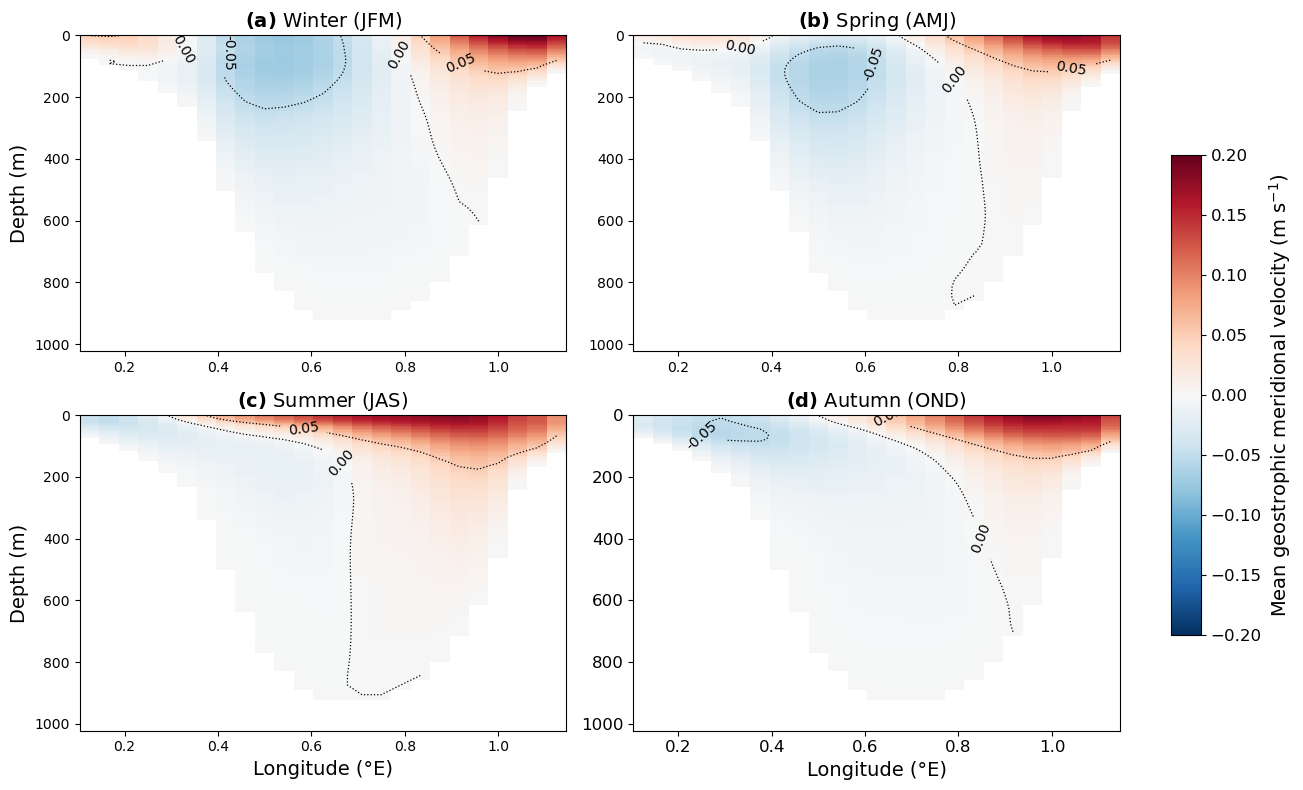

In [ ]:
import string

seasons = {
    "Winter (JFM)": [1, 2, 3],
    "Spring (AMJ)": [4, 5, 6],
    "Summer (JAS)": [7, 8, 9],
    "Autumn (OND)": [10, 11, 12],
}

seasonal_vo = {}

for name, months in seasons.items():
    mask = mod.time.dt.month.isin(months)
    vo_season = mod.vgeo3d2.where(mask, drop=True).mean("time")
    seasonal_vo[name] = vo_season

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs = axs.ravel()

norm = TwoSlopeNorm(vmin=-0.2, vcenter=0, vmax=0.2)
contour_levels = [-0.05, 0, 0.05]
for i, (ax, (name, vo_season)) in enumerate(zip(axs, seasonal_vo.items())):
    im = ax.pcolormesh(mod.lon, mod.depth, vo_season, shading="auto", cmap="RdBu_r", norm=norm)
    cs = ax.contour(
        mod.lon,
        mod.depth,
        vo_season,
        levels=contour_levels,
        colors="k",
        linestyles=":",
        linewidths=0.9,
    )

    ax.clabel(cs, inline=True, fontsize=10, fmt="%.2f")
    ax.set_title(r"$\mathbf{(" + string.ascii_lowercase[i] + ")}$ " + name, fontsize=14)
    ax.invert_yaxis()

    if i >= 2:
        ax.set_xlabel("Longitude (°E)", fontsize=14)
    else:
        ax.set_xlabel("")

    if i % 2 == 0:
        ax.set_ylabel("Depth (m)", fontsize=14)
    else:
        ax.set_ylabel("")

cax = fig.add_axes([0.98, 0.2, 0.025, 0.6])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Mean geostrophic meridional velocity (m s$^{-1}$)", fontsize=14)
cbar.ax.tick_params(labelsize=12)
ax.tick_params(axis="both", labelsize=12)

plt.tight_layout(rect=[0, 0, 0.95, 1])
plt.savefig("../../figures/figS4.png", dpi=300, bbox_inches="tight")
plt.show()

## Fig. S5: glider transport during the DANA

The glider transport "this study" is computed from the geostrophic velocity of each section
(`vgeo_gliders.py`), integrated over depth and across the section.

In [25]:
df_transport = pd.read_csv("../../results/vgeo2_transport_glider_full_depth_dana.csv", parse_dates=["time"])

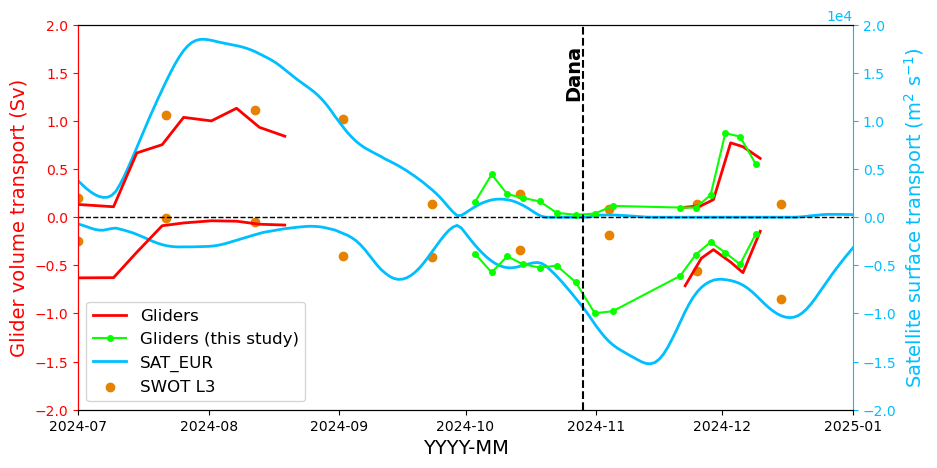

In [26]:
fig, axes = plt.subplots(1, 1, figsize=(10, 5), sharex=True)

ax1 = axes

plot_gliders(
    ax1,
    tgl,
    glider.northward_transport[idx_glider:],
    tgl,
    glider.southward_transport[idx_glider:],
    "#FF0000",
    "Gliders",
)

axx = ax1.twinx()

plot_gliders(
    axx,
    transeur_north.time[idx_eur:],
    transeur_north[idx_eur:],
    transeur_south.time[idx_eur:],
    transeur_south[idx_eur:],
    "#00BFFF",
    "SAT_EUR",
)

ax1.plot(
    df_transport["time"],
    df_transport["transport_north"],
    color="#09FF00",
    marker="o",
    markersize=4,
    linewidth=1.5,
)

ax1.plot(
    df_transport["time"],
    df_transport["transport_south"],
    color="#09FF00",
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Gliders (this study)",
)

axx.scatter(swot_time, swot_south, color="#E68200")
axx.scatter(swot_time, swot_north, color="#E68200", label="SWOT L3")

ax1.axhline(0, color="k", lw=1, linestyle="--")
ax1.set_ylabel("Glider volume transport (Sv)", fontsize=14)
axx.set_ylabel(r"Satellite surface transport (m$^{2}$ s$^{-1}$)", fontsize=14)
axx.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))

axx.set_zorder(0)
ax1.set_zorder(1)
ax1.patch.set_visible(False)

ax1.spines["left"].set_color("#FF0000")
ax1.yaxis.label.set_color("#FF0000")
ax1.tick_params(axis="y", colors="#FF0000")
ax1.set_xlabel("YYYY-MM", fontsize=14)

ax1.spines["right"].set_color("none")
axx.spines["right"].set_color("#00BFFF")
axx.yaxis.label.set_color("#00BFFF")
axx.tick_params(axis="y", colors="#00BFFF")

ax1.set_ylim(-2, 2)
axx.set_ylim(-20000, 20000)

lines_ax1, labels_ax1 = ax1.get_legend_handles_labels()
lines_axx, labels_axx = axx.get_legend_handles_labels()
ax1.legend(lines_ax1 + lines_axx, labels_ax1 + labels_axx, fontsize=12, loc="lower left")

date_dana = pd.Timestamp("2024-10-29")

ax1.axvline(date_dana, color="k", linestyle="--", linewidth=1.5, zorder=10)

ax1.text(
    date_dana,
    0.95,
    "Dana",
    transform=ax1.get_xaxis_transform(),
    rotation=90,
    va="top",
    ha="right",
    fontsize=14,
    fontweight="bold",
    color="k",
)
ax1.set_xlim(pd.Timestamp("2024-07-01"), pd.Timestamp("2025-01-01"))

plt.savefig("../../figures/figS5.png", dpi=300, bbox_inches="tight")
plt.show()